# Bayesian hyperparameter optimisation: chosen model

This notebook reproduces the **five Optuna TPE trials** for Histogram Gradient Boosting (HGB), then compares the untuned baseline and tuned model on exactly the same training trips, grouped CV folds, student-test trips, six candidate arcs per GPS point, and sampled observations. Saved outputs are from a real run. No reserved evaluator trips are used.

The target is **mean three-fold grouped training-CV macro F1**. Model family selection was also based on grouped training CV. Student-test metrics below are reporting-only, not the optimisation target.

## 1. Data and evaluation setup

Training: 80 trips, at most 120 GPS observations per trip; six candidate road arcs per observation. Student-test: 10 trips, at most 250 GPS observations per trip. The labels are **proxy pointwise labels** made by choosing the nearest arc on the provided reference route; the source does not contain a verified arc ID for each GPS observation. GroupKFold keeps whole trips together and prevents observations from the same trip appearing in both training and validation folds.

In [1]:
import os
from pathlib import Path
from contextlib import redirect_stdout
from io import StringIO
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from train import collect, grouped_cv, score_model

DATA_ROOT = Path(os.environ.get("PATHSNAP_DATA_ROOT", "data"))
assert (DATA_ROOT / "train").is_dir() and (DATA_ROOT / "student_test").is_dir(), DATA_ROOT
with redirect_stdout(StringIO()):
    X, y, groups, _ = collect(DATA_ROOT / "train", 120)
    _, _, _, test_trips = collect(DATA_ROOT / "student_test", 250)
print(f"Training rows: {len(y):,}; student-test trips: {len(test_trips)}; positive-label share: {y.mean():.2%}")
print("The same X, y, groups, and test_trips objects are used for both model versions.")

C:\Users\athar\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Training rows: 57,600; student-test trips: 10; positive-label share: 15.84%
The same X, y, groups, and test_trips objects are used for both model versions.


## 2. Search design: questions 1–4

Optuna's **TPE (Tree-structured Parzen Estimator)** sampler is a Bayesian/sequential search method. It uses results from earlier trials to suggest later settings; it is **not a Gaussian-process search**.

| Hyperparameter | Meaning | Range/distribution |
|---|---|---|
| max_iter | Maximum boosting rounds / trees | Integer, 40–120 |
| max_leaf_nodes | Maximum leaf nodes in each tree; controls complexity | Integer, 10–40 |
| learning_rate | Size of each boosting update | Float, 0.03–0.20 on a log scale |

We ran **five trials**, seed 42. Each trial constructs HGB with those three values and random_state=42, then maximises mean macro F1 over three GroupKFold training folds. Other HGB settings use library defaults during the search, including l2_regularization=0.0. The untuned baseline uses max_iter=80, max_leaf_nodes=25, learning_rate=0.1, and l2_regularization=0.1. The final tuned model is constructed with the same fixed settings as the search candidate, so the search score matches the model configuration.

In [2]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
def objective(trial):
    candidate = HistGradientBoostingClassifier(
        max_iter=trial.suggest_int("max_iter", 40, 120),
        max_leaf_nodes=trial.suggest_int("max_leaf_nodes", 10, 40),
        learning_rate=trial.suggest_float("learning_rate", 0.03, 0.20, log=True),
        random_state=42,
    )
    return float(np.mean(grouped_cv(candidate, X, y, groups, folds=3)))

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=5)
trials = pd.DataFrame([{"trial": t.number + 1, "CV macro F1": t.value, **t.params} for t in study.trials])
display(trials.style.format({"CV macro F1": "{:.4f}", "learning_rate": "{:.4f}"}))
print("Best settings:", study.best_params)
print(f"Best search objective: {study.best_value:.4f}")

,trial,CV macro F1,max_iter,max_leaf_nodes,learning_rate
0,1,0.7861,70,39,0.1203
1,2,0.7863,88,14,0.0403
2,3,0.7867,44,36,0.0938
3,4,0.7889,97,10,0.1889
4,5,0.7874,107,16,0.0424


Best settings: {'max_iter': 97, 'max_leaf_nodes': 10, 'learning_rate': 0.1889028280863132}
Best search objective: 0.7889


## 3. Fair untuned-versus-tuned comparison: questions 5–6

Both versions use the **same training matrix, grouped folds, student-test rows, score_model function, and Viterbi decoder**. The untuned settings are the original fixed HGB baseline. The tuned settings are the best Optuna trial. Candidate macro F1 is the average of the negative- and positive-class F1 scores; Top-1 and after-Viterbi accuracy compare against the proxy reference arc per GPS observation. Lower log loss is better. Inference timing is noisy on a single short run, so it is supporting evidence rather than a decisive ranking.

,CV macro F1,Student Top-1 proxy accuracy,Student candidate macro F1,Student candidate log loss,Inference seconds (sampled trips),Student after-Viterbi proxy accuracy,Route continuity before Viterbi,Route continuity after Viterbi,Continuity change (percentage points)
Untuned HGB,0.7876,0.7504,0.8105,0.2279,0.2638,0.7640,0.6076,0.7201,11.2450
Tuned HGB,0.7889,0.7540,0.8100,0.2280,0.0373,0.7672,0.6036,0.7197,11.6064
Tuned − untuned,0.0012,0.0036,-0.0005,0.0001,-0.2265,0.0032,-0.0040,-0.0004,0.3614


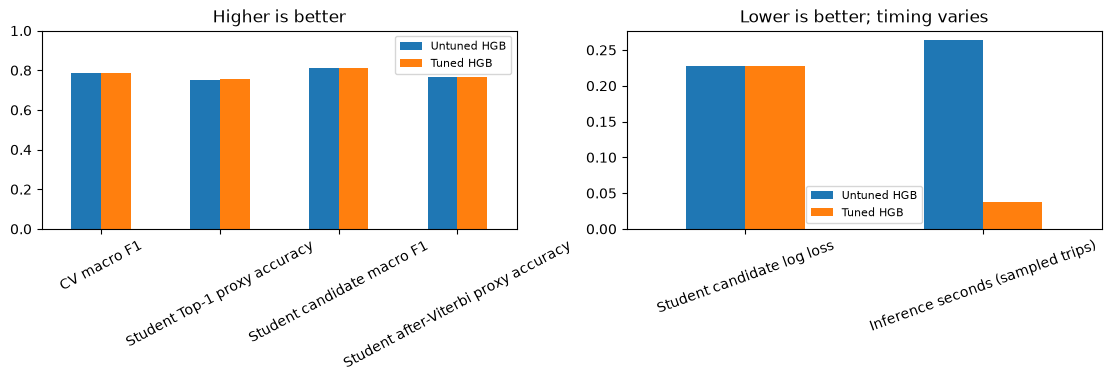

In [3]:
baseline = HistGradientBoostingClassifier(max_iter=80, max_leaf_nodes=25,
    learning_rate=0.1, l2_regularization=0.1, random_state=42)
tuned = HistGradientBoostingClassifier(**study.best_params, random_state=42)
records = {}
for name, model in [("Untuned HGB", baseline), ("Tuned HGB", tuned)]:
    cv = grouped_cv(model, X, y, groups, folds=3)
    model.fit(X, y)
    student = score_model(model, test_trips)
    records[name] = {
        "CV macro F1": float(np.mean(cv)),
        "Student Top-1 proxy accuracy": student["mean_trip_top1_accuracy"],
        "Student candidate macro F1": student["candidate_macro_f1"],
        "Student candidate log loss": student["log_loss"],
        "Inference seconds (sampled trips)": student["inference_seconds_total"],
        "Student after-Viterbi proxy accuracy": student["mean_trip_accuracy_viterbi"],
        "Route continuity before Viterbi": student["mean_continuity_classifier"],
        "Route continuity after Viterbi": student["mean_continuity_viterbi"],
        "Continuity change (percentage points)": 100*(student["mean_continuity_viterbi"]-student["mean_continuity_classifier"]),
    }
comparison = pd.DataFrame(records).T
comparison.loc["Tuned − untuned"] = comparison.loc["Tuned HGB"] - comparison.loc["Untuned HGB"]
display(comparison.style.format("{:.4f}"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout="constrained")
comparison.loc[["Untuned HGB", "Tuned HGB"],
    ["CV macro F1", "Student Top-1 proxy accuracy", "Student candidate macro F1",
     "Student after-Viterbi proxy accuracy"]].T.plot.bar(ax=axes[0], ylim=(0, 1), rot=28)
axes[0].set_title("Higher is better"); axes[0].legend(fontsize=8)
comparison.loc[["Untuned HGB", "Tuned HGB"],
    ["Student candidate log loss", "Inference seconds (sampled trips)"]].T.plot.bar(ax=axes[1], rot=20)
axes[1].set_title("Lower is better; timing varies"); axes[1].legend(fontsize=8)
plt.show()

In [4]:
delta = comparison.loc["Tuned − untuned"]
print(f"Grouped CV macro F1: {comparison.loc['Untuned HGB','CV macro F1']:.4f} → {comparison.loc['Tuned HGB','CV macro F1']:.4f} ({100*delta['CV macro F1']:+.2f} percentage points).")
print(f"Student Top-1 proxy accuracy: {100*comparison.loc['Untuned HGB','Student Top-1 proxy accuracy']:.2f}% → {100*comparison.loc['Tuned HGB','Student Top-1 proxy accuracy']:.2f}%.")
print(f"Student candidate macro F1: {comparison.loc['Untuned HGB','Student candidate macro F1']:.4f} → {comparison.loc['Tuned HGB','Student candidate macro F1']:.4f}.")
print(f"Student candidate log loss: {comparison.loc['Untuned HGB','Student candidate log loss']:.4f} → {comparison.loc['Tuned HGB','Student candidate log loss']:.4f} (lower is better).")
print(f"Student after-Viterbi proxy accuracy: {100*comparison.loc['Untuned HGB','Student after-Viterbi proxy accuracy']:.2f}% → {100*comparison.loc['Tuned HGB','Student after-Viterbi proxy accuracy']:.2f}%.")
print("Conclusion: tuning improved the CV objective and some route metrics, but it did not improve every metric. Do not claim universal improvement.")

Grouped CV macro F1: 0.7876 → 0.7889 (+0.12 percentage points).
Student Top-1 proxy accuracy: 75.04% → 75.40%.
Student candidate macro F1: 0.8105 → 0.8100.
Student candidate log loss: 0.2279 → 0.2280 (lower is better).
Student after-Viterbi proxy accuracy: 76.40% → 76.72%.
Conclusion: tuning improved the CV objective and some route metrics, but it did not improve every metric. Do not claim universal improvement.


## Viva answers and limitations

1. **Why HGB?** It had the highest grouped training-CV macro F1 among the five initial families. Its nonlinear trees can combine distance, direction, movement, and road length clues. Student-test outcomes were not used to choose the family.
2. **Why Bayesian optimisation?** TPE uses previous trial scores to guide later suggestions. Five trials were a small, time-limited search; they do not prove a global optimum.
3. **What was optimised?** Mean three-fold GroupKFold macro F1 on training trips. The student-test set was evaluated afterward.
4. **What were the best values?** Read the executed trial table above. The selected trial used max_iter=97, max_leaf_nodes=10, and learning_rate≈0.1889 in the recorded run.
5. **Did accuracy improve?** Report each metric separately from the comparison table. CV macro F1 and student Top-1/after-Viterbi proxy accuracy improved slightly; candidate macro F1 and log loss did not. Inference time varies by run.
6. **What are hidden layers?** There are **no neural-network hidden layers** in Histogram Gradient Boosting. It is an ensemble of decision trees. The later route decoder has **hidden states** (candidate road arcs), which are a different concept.
7. **Why can test metrics disagree?** Optuna targets one metric on training CV. Candidate classification, probability calibration, and full route decoding measure different behavior. Five trials and proxy labels add uncertainty.
8. **What would improve the evidence?** More grouped-CV folds or repeated seeds, a larger training-only search, calibration checks, and independent verified pointwise labels. Do not tune on the student-test or reserved evaluator trips.